# State of the art: penalised trees, glass-box boosting, monotone boosting and a foundation model against the scorecard

**Question:** Which of the current challengers to a WoE scorecard earns its place on 9,000 held-out Taiwan cards once ranking, calibration and readability are all weighed, and does the answer change on a small sample?

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 01 to 05 of this topic
- **Reading time:** about 70 minutes

## Objectives

By the end of this notebook you can:

- name the current challengers to a WoE scorecard in credit scoring (penalised trees, explainable boosting, monotone gradient boosting, a tabular foundation model), what each claims and the source of the claim;
- run the engine on the eight models of the ladder, rebuilt from their committed curves and tables, with the AUC, the chi-square over grades, the level test and the challenger protocol, and check the engine against scikit-learn as an independent reference;
- open the glass-box components of the committed models: the rules and their stability, the shape functions and the monotone constraints;
- read what the isotonic calibration did to each challenger, and what changes on a small sample.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 scikit-learn==1.9.1
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from sklearn.metrics import brier_score_loss, roc_auc_score

from riskvalidation.ml.challenger import grade_disagreement, paired_brier_bootstrap
from riskvalidation.validation.calibration import pd_brier, pd_chi2_grades, pd_ece, pd_hosmer_lemeshow, pd_jeffreys
from riskvalidation.validation.discrimination import auc_with_variance, disc_auc, disc_ks
from riskvalidation.validation.ml import challenger_brier

for name in ("riskvalidation", "numpy", "scipy", "matplotlib", "scikit-learn"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2
scikit-learn 1.9.1


## Data

The comparison reads five committed files of case C01 (retail credit-card PD):

- `data/derived/C01/holdout.json`: the ladder on the 9,000 held-out Taiwan cards (UCI Taiwan credit-card file, Yeh, 2009; owner: UCI Machine Learning Repository; CC BY 4.0, licence class `mirror-allowed`; https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients): ROC and CAP curves, grades, reliability bins before and after calibration, a 50-card sample scored by two models, and the battery of tests.
- `data/derived/C01/models-taiwan.json`: what each model learned (rules, shape functions, constraints, calibration maps).
- `data/derived/C01/small-sample.json`: the same cards scored by models fitted on only 2,000 rows.
- `data/derived/C01/german-twin.json` and `data/derived/C01/models-german.json`: the Statlog German credit data (1,000 records; UCI; CC BY 4.0, licence class `mirror-allowed`; https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data), a holdout of 300 records scored by the ladder and by the tabular foundation model TabPFN.

The next cell loads the five files and prints the ladder. The notebook pins `scikit-learn` as the independent reference implementation of the AUC and the Brier score; the models themselves (penalised trees, boosting machine, boosted trees, TabPFN) were fitted by the pipeline on raw data that lives outside the repository.

In [2]:
# Load the committed files of case C01: the ladder on the 9000 cards, the fitted models and the two small-data cases
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C01"
files = ("holdout.json", "models-taiwan.json", "small-sample.json", "german-twin.json", "models-german.json")
holdout, models, small, twin, models_german = [json.loads((derived / n).read_text(encoding="utf-8")) for n in files]
tests, rungs = holdout["tests"], holdout["outputs"]["rungs"]
ladder = [m["id"] for m in holdout["model"]]
details = {m["id"]: m["details"] for m in models["model"]}
policy = rv.default_policy()
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "none"}
print("models in the ladder:", ladder)
print("baked by riskvalidation", holdout["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

models in the ladder: ['P0-constant', 'P0-single', 'P1-scorecard', 'P2a-l1', 'P2b-pltr', 'P3-ebm', 'P4-lightgbm', 'P4-xgboost']
baked by riskvalidation 1.0.1 | installed 1.0.1


## Method

### The protocol of the comparison

Every challenger is judged on the same 9,000 cards by the same battery, so that a difference is a property of the model and not of the sample. Four measurements decide, and each has its tool in the engine. **Ranking**: the AUC and, for two models scored on the same cards, the paired DeLong test of notebook 03 (DeLong, DeLong and Clarke-Pearson, 1988). **Fit by grade**: the chi-square over the grades of the master scale (BCBS, 2005). **Level**: the one-sided Jeffreys test on the whole holdout. **Challenger protocol**: the engine's paired bootstrap of the Brier difference and the share of cards that change grade between two models. The 9,000 cards are not in the repository, but each model's CAP curve, grade table and reliability bins are, so the cell rebuilds, for each of the eight models, a vector of 9,000 risk values and outcomes from the 100 CAP steps (90 cards each) and runs `auc_with_variance` and `disc_ks` on it. The AUC and its 95% half-width come back with the KS; the figure draws them next to the AUC the pipeline committed for the same cards.

P0-constant AUC, half-width, KS: 0.511 0.0143 0.0396
P0-single AUC, half-width, KS: 0.6994 0.0145 0.3573
P1-scorecard AUC, half-width, KS: 0.7586 0.0127 0.3956
P2a-l1 AUC, half-width, KS: 0.7586 0.0127 0.3956
P2b-pltr AUC, half-width, KS: 0.775 0.0121 0.4202
P3-ebm AUC, half-width, KS: 0.7753 0.012 0.4249
P4-lightgbm AUC, half-width, KS: 0.7778 0.0119 0.4249
P4-xgboost AUC, half-width, KS: 0.7765 0.012 0.4235
rebuilt cards: 9000
AUC gain over the scorecard: {'P2a-l1': -0.0, 'P2b-pltr': 0.0163, 'P3-ebm': 0.0167, 'P4-lightgbm': 0.0191, 'P4-xgboost': 0.0178}


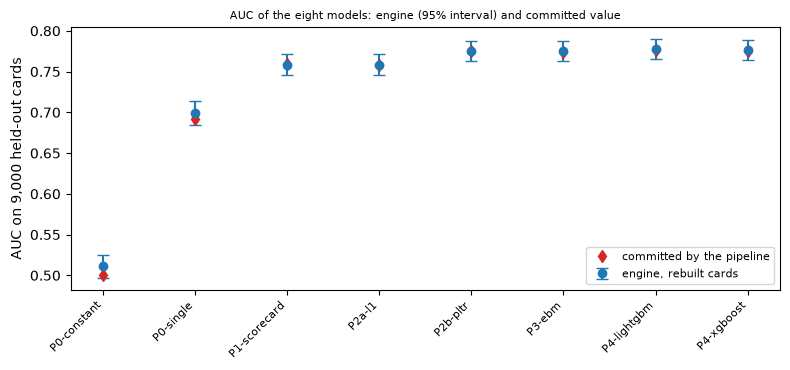

In [3]:
# Rebuild 9000 cards from the CAP steps of every model and run the engine's AUC, its variance and the KS on them
n_cards, n_defaults = holdout["outputs"]["n"], holdout["outputs"]["defaults"]
vectors, engine = {}, {}
for rung in ladder:
    per_slice = np.rint(np.diff(np.array(rungs[rung]["cap"]["defaults"])) * n_defaults).astype(int)
    size = n_cards // len(per_slice)
    risk = np.repeat(np.arange(len(per_slice), 0, -1), size)
    flags = np.concatenate([np.r_[np.ones(d), np.zeros(size - d)] for d in per_slice])
    value, variance, _, _ = auc_with_variance(risk, flags)
    half = 1.96 * variance ** 0.5
    ks = disc_ks(risk, flags, policy=policy, model_id=rung)
    vectors[rung], engine[rung] = (risk, flags), (value, half, ks.metric)
    print(rung, "AUC, half-width, KS:", round(value, 4), round(half, 4), round(ks.metric, 4))
committed = {t["model_id"]: t["metric"] for t in tests if t["test_id"] == "disc.auc" and t["segment"] == "portfolio"}
base = engine["P1-scorecard"][0]
gains = {r: round(engine[r][0] - base, 4) for r in ladder[3:]}
print("rebuilt cards:", n_cards)
print("AUC gain over the scorecard:", gains)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(range(len(ladder)), [engine[r][0] for r in ladder], yerr=[engine[r][1] for r in ladder], fmt="o",
            capsize=4, label="engine, rebuilt cards")
ax.plot(range(len(ladder)), [committed[r] for r in ladder], "d", color="tab:red", label="committed by the pipeline")
ax.set_xticks(range(len(ladder)), ladder, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("AUC on 9,000 held-out cards")
ax.set_title("AUC of the eight models: engine (95% interval) and committed value", fontsize=8)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The engine ranks the scorecard and the penalised logistic regression together at 0.7586, the penalised trees, the boosting machine and the two boosted-tree models higher, at 0.775 to 0.7778, and the one-variable baseline at 0.6994. A gain of 0.016 to 0.019 AUC points for the richer models is the size the benchmarks of the next section report, and it is below the 95% half-width of about 0.012 of each estimate, so the intervals overlap. Two artefacts of the rebuilding show in the figure: the one-variable model is above its committed 0.6917, and the constant model is at 0.511 where the true AUC is 0.5. In both, many cards share one PD, and cutting a block of ties into slices makes the rebuilt vector order cards that the model cannot order. For models with many distinct scores the red diamonds sit on the blue points.

### Fit by grade and level

Ranking and calibration are separate properties. The chi-square over grades takes the cards, defaults and mean PD of each grade and rejects when any grade departs from its PD in either direction. The Jeffreys test takes the whole holdout and rejects only when defaults exceed what the average PD allows. The cell runs both on the grade table of every model and draws the p-value of the chi-square, coloured by the light the engine gives.

P0-constant chi-square over grades, p, light: 0.9942 green
   level test, Jeffreys p: 0.496
P0-single chi-square over grades, p, light: 0.5982 green
   level test, Jeffreys p: 0.264
P1-scorecard chi-square over grades, p, light: 0.0264 amber
   level test, Jeffreys p: 0.31
P2a-l1 chi-square over grades, p, light: 0.0405 amber
   level test, Jeffreys p: 0.314
P2b-pltr chi-square over grades, p, light: 0.4641 green
   level test, Jeffreys p: 0.307
P3-ebm chi-square over grades, p, light: 0.0 red
   level test, Jeffreys p: 0.778
P4-lightgbm chi-square over grades, p, light: 0.0007 red
   level test, Jeffreys p: 0.82
P4-xgboost chi-square over grades, p, light: 0.0 red
   level test, Jeffreys p: 0.836


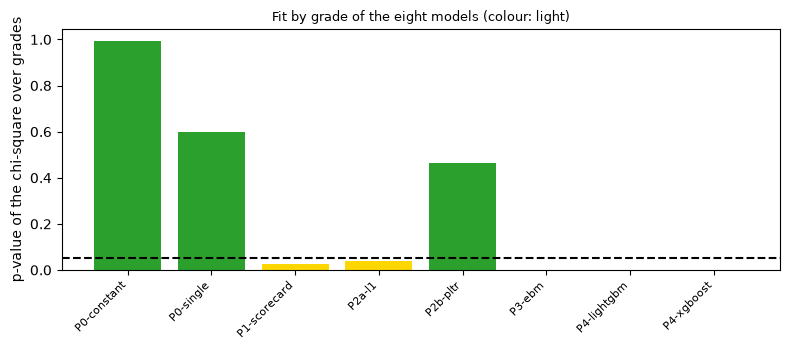

In [4]:
# The engine's chi-square over grades and the level test of every model, from its committed grade table
colors = {"green": "tab:green", "amber": "gold", "red": "tab:red", "not_evaluated": "lightgray"}
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, rung in enumerate(ladder):
    grades = [g for g in rungs[rung]["grades"] if g["n"] > 0]
    n_g, d_g, pd_g = [g["n"] for g in grades], [g["d"] for g in grades], [g["pd"] for g in grades]
    kw = dict(policy=policy, model_id=rung, segment="portfolio")
    chi = pd_chi2_grades(n_g, d_g, pd_g, **kw)
    level = pd_jeffreys(sum(n_g), sum(d_g), sum(n * p for n, p in zip(n_g, pd_g)) / sum(n_g), **kw)
    ax.bar(k, chi.p_value, color=colors[chi.light.value])
    print(rung, "chi-square over grades, p, light:", round(chi.p_value, 4), LIGHT[chi.light.value])
    print("   level test, Jeffreys p:", round(level.p_value, 3))
ax.axhline(0.05, color="black", linestyle="--")
ax.set_xticks(range(len(ladder)), ladder, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("p-value of the chi-square over grades")
ax.set_title("Fit by grade of the eight models (colour: light)", fontsize=9)
fig.tight_layout()
plt.show()

The chi-square over grades is green for the constant model (0.9942), the one-variable baseline (0.5982) and the penalised trees (0.4641), amber for the scorecard (0.0264) and the penalised logistic regression (0.0405), and red for the boosting machine (0.0), LightGBM (0.0007) and XGBoost (0.0). The level test is green for all eight (p between 0.264 and 0.836). So the models that rank best have the right average and the wrong fit by grade, and the penalised trees are the one richer model that keeps both. A better ranker is not a better calibrated one, which is why the product recalibrates its challengers (Step 6 of the state of the art).

### The engine's challenger protocol

The engine's ML module compares a challenger with the champion on the same cards. `paired_brier_bootstrap` resamples the cards, computes the Brier score of both PDs on each resample and returns the difference with a 95% interval; `challenger_brier` wraps it as a test result; `grade_disagreement` returns the share of cards whose grade differs by two notches or more between the two PDs. Only 50 cards carry both the scorecard's PD and the boosting machine's score, so the cell runs the protocol on them, with 2,000 seeded resamples.

In [5]:
# The engine's challenger protocol on the 50 cards: paired Brier bootstrap and the share of cards that change grade
y50 = np.array(holdout["outputs"]["sample"]["targets"])
p_card = np.array(holdout["outputs"]["sample"]["scorecard_pd"])
p_ebm = 1.0 / (1.0 + np.exp(-np.array(holdout["outputs"]["sample"]["ebm_logit"])))
paired = paired_brier_bootstrap(p_card, p_ebm, y50, n_boot=2000, seed=7)
verdict = challenger_brier("P3-ebm", paired)
edges = np.array([g["hi"] for g in rungs["P1-scorecard"]["grades"]][:-1])
print("paired Brier difference and 95% interval:", round(paired.diff, 4), round(paired.lo, 4), round(paired.hi, 4))
print("p-value of the bootstrap test and light:", verdict.p_value, LIGHT[verdict.light.value])
print("share of cards that change by two grades:", round(grade_disagreement(p_card, p_ebm, edges, 2), 3))

paired Brier difference and 95% interval: -0.0039 -0.0165 0.0084
p-value of the bootstrap test and light: None green
share of cards that change by two grades: 0.02


The Brier difference between the boosting machine and the scorecard is -0.0039, with an interval from -0.0165 to 0.0084 that includes zero: on 50 cards the challenger is not shown to forecast better. The test result carries no p-value (the default policy holds no threshold for the Brier comparison, so the light is green by default and the interval is the evidence), and only 0.02 of the cards, one of 50, changes by two grades between the two PDs. The protocol works; the sample is far too small to use it for a decision, which the benchmarks' authors would say first.

## State of the art

### The benchmark evidence

The research of this product (dossier 04, section B.4) read the credit-scoring benchmarks. Four findings frame the comparison, each with its source:

| Source | Design | Finding relevant here |
|---|---|---|
| Baesens et al. (2003), https://doi.org/10.1057/palgrave.jors.2601545 | 8 real credit datasets, AUC and accuracy with significance tests | support-vector machines and neural networks perform very well, and simple logistic regression and linear discriminant analysis also perform very well |
| Lessmann, Baesens, Seow and Thomas (2015), https://doi.org/10.1016/j.ejor.2015.05.030 | 41 classifiers, 8 retail datasets, six measures | several classifiers beat logistic regression significantly, especially heterogeneous ensembles; random forest is the recommended minimum benchmark; report at least the AUC, the partial Gini and the Brier score |
| Gunnarsson et al. (2021), https://doi.org/10.1016/j.ejor.2021.03.006 | multilayer perceptron and deep belief network against logistic regression, trees, random forest and XGBoost | XGBoost is the best method, and deep networks do not outperform shallower counterparts |
| Grinsztajn, Oyallon and Varoquaux (2022), https://arxiv.org/abs/2207.08815 | 45 general tabular datasets (not credit-specific) | tree-based models remain state of the art on medium-sized data of about 10,000 samples |

The synthesis the product's ladder follows: tree ensembles beat plain logistic regression on most retail benchmarks, by a few AUC points; logistic regression on well-binned WoE stays competitive; interpretability can be recovered with constrained or glass-box models, the natural challengers of a regulated PD model; and calibration is separate from discrimination.

### An independent implementation of the measures

Before trusting a comparison, the measures themselves are checked against an implementation the product did not write. The pinned `scikit-learn` implements `roc_auc_score` and `brier_score_loss`. The cell runs them on the same vectors as the engine, the AUC on the cards rebuilt from the CAP steps and the Brier score on the cards rebuilt from the reliability bins (each card takes the mean PD of its bin, each bin its observed number of defaults), and draws the two sets of values against each other for the eight models.

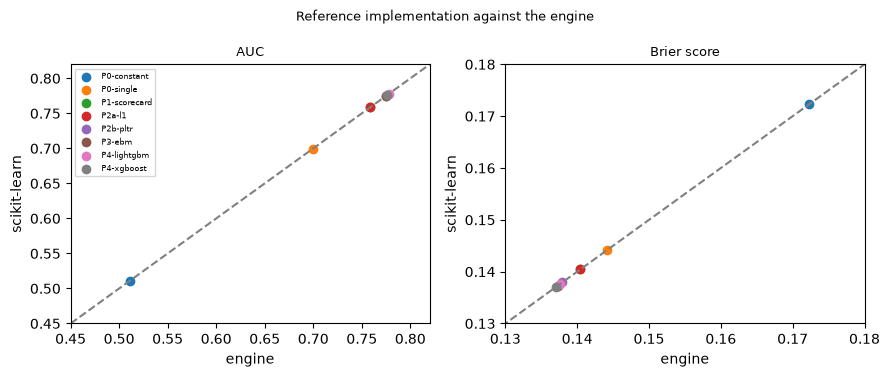

largest gap of AUC and of Brier between the two: 0.0 0.0


In [6]:
# scikit-learn on the same cards: AUC on the rebuilt cards, Brier score on the cards rebuilt from the reliability bins
gap_auc = gap_brier = 0.0
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.8))
for rung in ladder:
    risk, flags = vectors[rung]
    bins_ = rungs[rung]["reliability"]
    pd_cards = np.concatenate([np.full(b["n"], b["pd"]) for b in bins_])
    hits = [int(round(b["dr"] * b["n"])) for b in bins_]
    flags_pd = np.concatenate([np.r_[np.ones(k), np.zeros(b["n"] - k)] for b, k in zip(bins_, hits)])
    reference = (roc_auc_score(flags, risk), brier_score_loss(flags_pd, pd_cards))
    ours = (engine[rung][0], pd_brier(flags_pd, pd_cards, policy=policy, model_id=rung, segment="portfolio").metric)
    gap_auc, gap_brier = max(gap_auc, abs(reference[0] - ours[0])), max(gap_brier, abs(reference[1] - ours[1]))
    left.scatter(ours[0], reference[0], label=rung)
    right.scatter(ours[1], reference[1])
for ax, name in ((left, "AUC"), (right, "Brier score")):
    ax.plot([0.1, 1], [0.1, 1], color="gray", linestyle="--")
    ax.set_xlabel("engine")
    ax.set_ylabel("scikit-learn")
    ax.set_title(name, fontsize=9)
left.set_xlim(0.45, 0.82)
left.set_ylim(0.45, 0.82)
right.set_xlim(0.13, 0.18)
right.set_ylim(0.13, 0.18)
left.legend(fontsize=6)
fig.suptitle("Reference implementation against the engine", fontsize=9)
fig.tight_layout()
plt.show()
print("largest gap of AUC and of Brier between the two:", round(gap_auc, 6), round(gap_brier, 6))

The points of the eight models fall on the diagonal in both panels, and the largest gap between the two implementations is below one millionth for the AUC and for the Brier score (both print 0.0 at six decimals). The measures the notebook uses are therefore not an artefact of one implementation; what depends on the engine is the rebuilt vector and the policy, which the cells above state. The Brier panel is also the first view of how little the models differ as forecasts: all eight lie between 0.136 and 0.173.

### Penalised trees (PLTR) and the penalised logistic regression

Dumitrescu, Hue, Hurlin and Tokpavi (2022, https://doi.org/10.1016/j.ejor.2021.06.053) propose the **penalised logistic tree regression**: short decision trees are grown, each root-to-node path becomes a binary rule (such as "`PAY_0 <= 1.5`"), and the rules enter a logistic regression with an L1 penalty that keeps few of them. The research summary reports that it significantly beats logistic regression and is competitive with a random forest while keeping the readability of a logistic model. The product's rung P2b follows that design with scikit-learn trees and `LogisticRegression`, with its own rule extraction; rung P2a is the plain L1 logistic regression on the WoE variables. The cell draws the 12 rules with the largest coefficients among those the penalty kept, and prints how many candidate rules there were and how stable the selection is across 20 resamples (the mean Jaccard index of the selected sets, 1 for identical sets).

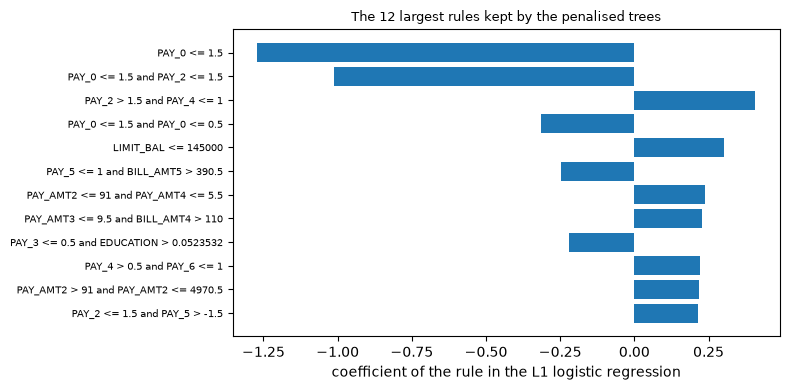

candidate rules and rules kept: 449 101
Jaccard of the selected sets, mean, min: 0.411 0.367


In [7]:
# The rules kept by the penalised trees (P2b): the 12 largest coefficients, and the stability of the selection
pltr = details["P2b-pltr"]
top = sorted(pltr["selected_rules"], key=lambda r: -abs(r["coefficient"]))[:12]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh([r["rule"][:44] for r in top][::-1], [r["coefficient"] for r in top][::-1], color="tab:blue")
ax.tick_params(axis="y", labelsize=7)
ax.set_xlabel("coefficient of the rule in the L1 logistic regression")
ax.set_title("The 12 largest rules kept by the penalised trees", fontsize=9)
fig.tight_layout()
plt.show()
stability = pltr["stability"]
print("candidate rules and rules kept:", pltr["n_candidate_rules"], len(pltr["selected_rules"]))
mean_j, min_j = stability["jaccard_mean"], stability["jaccard_min"]
print("Jaccard of the selected sets, mean, min:", round(mean_j, 3), round(min_j, 3))

The largest rule is `PAY_0 <= 1.5` with a coefficient of about -1.27, the same repayment status that carries the scorecard, and the next one, `PAY_0 <= 1.5 and PAY_2 <= 1.5`, also negative: rules are short conjunctions of at most two conditions, so each one is readable on its own. Of 449 candidate rules the penalty kept 101, and the selection is not stable: the mean Jaccard index across resamples is 0.411 and its minimum 0.367, so only about two fifths of the selected rules are shared between two resamples. The rules are a good reading of the model and a poor definition of it, since a different sample would give a different list with a similar performance.

### Explainable boosting (EBM and GA2M)

The generalised additive model with pairwise interactions (GA2M; Lou, Caruana, Gehrke and Hooker, 2013, https://doi.org/10.1145/2487575.2487579) and its boosted implementation, the explainable boosting machine (Nori, Jenkins, Koch and Caruana, 2019, https://arxiv.org/abs/1909.09223), model the log-odds as a sum of one-variable functions and a few pairwise terms,

$$g(\mathbb{E}[y]) = \beta_0 + \sum_j f_j(x_j) + \sum_{(i,j)} f_{ij}(x_i, x_j),$$

with $g$ the logit link and each $f_j$ learned by cyclic gradient boosting with a very low learning rate. The consequence for credit is that an EBM is a boosted scorecard: each $f_j$ can be read as a table of points and the reason codes of the main effects are exact. The committed fit exports its terms, and the cell draws the shape function of the credit limit and of the latest repayment status next to the contribution of the scorecard in its own bins, $\beta_j\,\mathrm{WoE}_{j,b}$ (notebook 01), both shifted to start at zero because the additive constants live in the intercept.

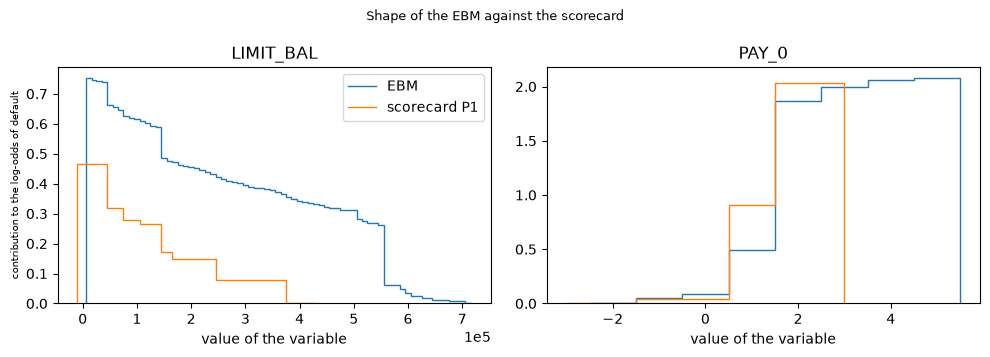

In [8]:
# The shape functions of the EBM against the contribution of the scorecard in its own bins, for two variables
export = details["P3-ebm"]["export"]
terms = {t["name"]: t for t in export["terms"] if len(t["features"]) == 1}
cuts = {f["name"]: f["levels"][0]["cuts"] for f in export["features"] if "cuts" in f["levels"][0]}
card = details["P1-scorecard"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, name in zip(axes, ("LIMIT_BAL", "PAY_0")):
    rows = [r for r in card["points_table"] if r["feature"] == name and r["count"] > 0]
    card_steps = np.array([card["coefficients"][name] * r["woe"] for r in rows])
    series = [(cuts[name], np.array(terms[name]["scores"][1:-1]), "EBM"),
              (card["bins"][name]["splits"], card_steps, "scorecard P1")]
    for c, scores, label in series:
        c = np.array(c, dtype=float)
        pad = max(float(np.diff(c).mean()) if len(c) > 1 else 1.0, 1.0)
        ax.stairs(scores - scores.min(), np.r_[c[0] - pad, c, c[-1] + pad], label=label)
    ax.set_title(name)
    ax.set_xlabel("value of the variable")
axes[0].ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
axes[0].set_ylabel("contribution to the log-odds of default", fontsize=7)
axes[0].legend()
fig.suptitle("Shape of the EBM against the scorecard", fontsize=9)
fig.tight_layout()
plt.show()

Both models say the same thing about the repayment status: almost no contribution for cards that paid duly, a rise near 0.5 to 1.5 months of delay and a plateau of about two log-odds units beyond it. The EBM is smoother, with fine steps where the scorecard has 4 or 8 bins, and for the credit limit it falls steadily and ends near zero, a shape the eight bins of the scorecard only approximate. That is what the product gets from the boosted version: the same additive reading with a finer curve. The shapes also say where the scorecard is coarse and the boosting machine might over-fit: the EBM places its own cut points at dozens of values, and nothing forbids it a non-monotone curve.

### Monotone gradient boosting

Gradient-boosted trees (LightGBM, XGBoost, CatBoost) accept a monotone constraint per variable, the same direction the scorecard imposes by its binning. The documentation of each engine states the caveats the research recorded: with the `hist` or `approx` tree methods XGBoost constraints can wipe out split candidates and give shallow trees (https://xgboost.readthedocs.io/en/stable/tutorials/monotonic.html); LightGBM offers `basic`, `intermediate` and `advanced` methods, of which `basic` over-constrains the predictions (https://lightgbm.readthedocs.io/en/latest/Parameters.html); and the `monotonize()` of the EBM is applied after the fit, one term at a time. The committed LightGBM fit uses the `advanced` method with the same constraints as the scorecard and stores a check, the partial-dependence curve of the model along a grid of each constrained variable. The cell compares the constraints with the scorecard's, prints the largest violation found and draws two curves.

constraints equal the scorecard's, largest violation: True 0.0


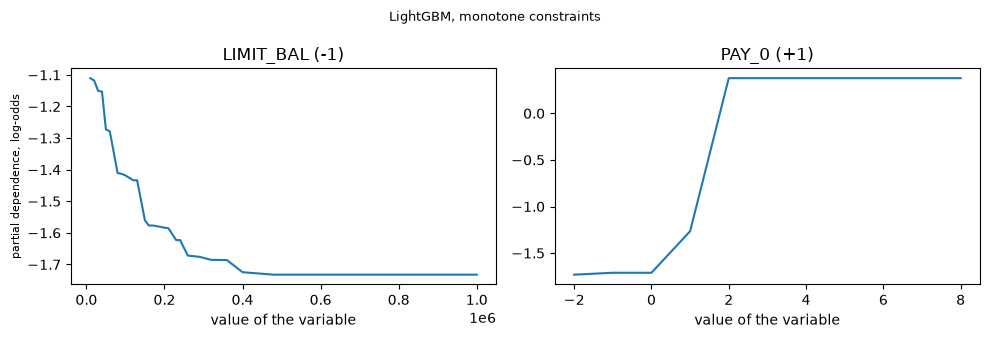

In [9]:
# The monotone constraints of LightGBM against the scorecard's, the stored check, and two partial-dependence curves
lgbm = details["P4-lightgbm"]
wanted = {v["name"]: v["monotone"] for v in models["fit"]["features"]}
check = lgbm["monotonicity"]
worst = max(f["max_violation"] for f in check["features"].values())
print("constraints equal the scorecard's, largest violation:", lgbm["constraints"] == wanted, worst)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, name in zip(axes, ("LIMIT_BAL", "PAY_0")):
    f = check["features"][name]
    ax.plot(f["grid"], f["pdp"])
    ax.set_title(f"{name} ({f['direction']:+d})")
    ax.set_xlabel("value of the variable")
axes[0].set_ylabel("partial dependence, log-odds", fontsize=8)
fig.suptitle("LightGBM, monotone constraints", fontsize=9)
fig.tight_layout()
plt.show()

The constraints of LightGBM equal the scorecard's (the comparison prints True) and the largest violation found along the grid is 0.0: the credit-limit curve never rises and the repayment-status curve never falls. The product therefore gets the direction the regulator reads in a scorecard out of a boosted-tree model, at 94 trees. What the figure does not show is where the constraint costs ranking, and the AUC of 0.7778 against 0.7586 says it costs little.

### Calibration after the ranking

Discrimination and calibration are separate properties, and two warnings from the research apply. Correcting a class imbalance by resampling (random under- or over-sampling, SMOTE) produces strongly miscalibrated models, with the minority-class probability over-estimated and no higher AUC (van den Goorbergh, van Smeden, Timmerman and Van Calster, 2022, https://doi.org/10.1093/jamia/ocac093); when a sample is balanced by design, the intercept must be corrected for the prior (King and Zeng, 2001, https://doi.org/10.1093/oxfordjournals.pan.a004868). C01 resamples nothing: its default rate is 22%. What the product does is fit a **post-hoc calibration map** on a slice of cards that neither the fit nor the test has seen, the isotonic regression (Zadrozny and Elkan, 2002, https://doi.org/10.1145/775047.775151), a monotone step function that cannot reorder the cards. The artifact stores the reliability bins before the map and after it. The cell draws both for the boosting machine beside the map itself, and prints the expected calibration error, $\mathrm{ECE} = \sum_b (n_b/N)\,|\overline{\mathrm{PD}}_b - \mathrm{DR}_b|$, of the three calibrated challengers before and after it.

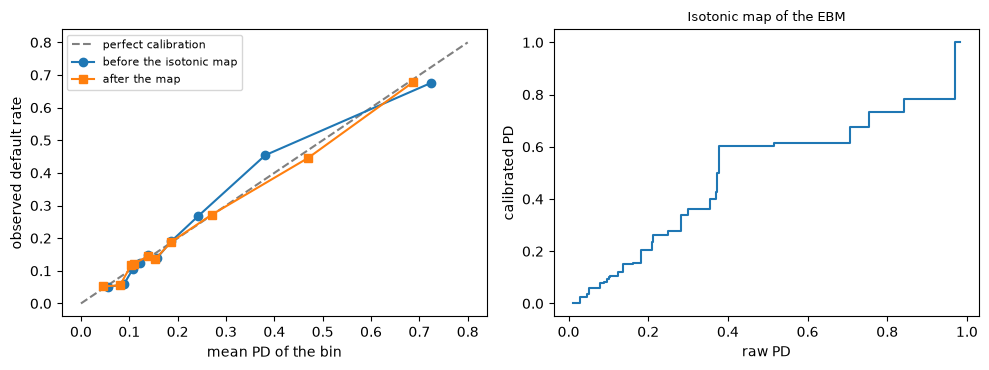

P3-ebm ECE before and after the map: 0.0218 0.0118
P4-lightgbm ECE before and after the map: 0.0121 0.0134
P4-xgboost ECE before and after the map: 0.0131 0.0124


In [10]:
# The isotonic map of the EBM, the reliability of its raw and calibrated PD, and the ECE of each challenger
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
raw, cal = rungs["P3-ebm"]["reliability_raw"], rungs["P3-ebm"]["reliability"]
left.plot([0, 0.8], [0, 0.8], color="gray", linestyle="--", label="perfect calibration")
left.plot([b["pd"] for b in raw], [b["dr"] for b in raw], marker="o", label="before the isotonic map")
left.plot([b["pd"] for b in cal], [b["dr"] for b in cal], marker="s", label="after the map")
left.set_xlabel("mean PD of the bin")
left.set_ylabel("observed default rate")
left.legend(fontsize=8)
mapping = next(m["calibration"] for m in models["model"] if m["id"] == "P3-ebm")
right.step(mapping["x"], mapping["y"], where="post")
right.set_xlabel("raw PD")
right.set_ylabel("calibrated PD")
right.set_title("Isotonic map of the EBM", fontsize=9)
fig.tight_layout()
plt.show()
for rung in ("P3-ebm", "P4-lightgbm", "P4-xgboost"):
    scores = []
    for key in ("reliability_raw", "reliability"):
        bins_ = rungs[rung][key]
        pd_cards = np.concatenate([np.full(b["n"], b["pd"]) for b in bins_])
        hits = [int(round(b["dr"] * b["n"])) for b in bins_]
        flags = np.concatenate([np.r_[np.ones(k), np.zeros(b["n"] - k)] for b, k in zip(bins_, hits)])
        scores.append(pd_ece(flags, pd_cards, bins=10, policy=policy, model_id=rung, segment="portfolio").metric)
    print(rung, "ECE before and after the map:", round(scores[0], 4), round(scores[1], 4))

Before the map the boosting machine under-predicts the bin near 0.38 and over-predicts the top one, with an ECE of 0.0218; after it the points sit on the diagonal and the ECE is 0.0118. The map is a staircase that is flat over much of the raw PD range, between 0.4 and 0.5 where it holds one value, which is how an isotonic map pools cards the model could not separate. It does not help every model: LightGBM was already near the diagonal (0.0121) and ends slightly worse (0.0134), and XGBoost improves from 0.0131 to 0.0124. Recalibration repairs a visible miscalibration and adds noise when there is none, and its slice must be big enough: the same chi-square over grades is still red for all three after it.

### Small data and the foundation model

Tabular foundation models are the open frontier of the research, strongest on small data (Hollmann et al., 2025, https://doi.org/10.1038/s41586-024-08328-6): TabPFN predicts by in-context learning and trains nothing per dataset. Its licence is part of the evidence. According to the research (read from the project's README, https://github.com/PriorLabs/TabPFN, on 2026-10-04) the code is Apache-2.0 while the weights are licensed per version: those of v2 under the Prior Labs License v1.1 (Apache 2.0 plus an attribution clause), those of later versions under a non-commercial licence that allows research and internal benchmarking but not production use. The product therefore carries it as an optional **research challenger** (rung P5), present only where its extra is installed. The credit-specific evidence found is a conference abstract with preliminary results and no numbers (UNVERIFIED beyond the abstract). The German twin has 1,000 records and a holdout of 300, the small-data case. The cell rebuilds the 300 German records and the 9,000 Taiwan cards scored by models fitted on 2,000 rows from their CAP steps, runs the engine's AUC on every rung, prints the engine and version of P5 and draws the three evaluation sets side by side.

P5 engine and version: tabpfn 9.1.0
engine AUC on the German twin: {'P0-constant': 0.48, 'P0-single': 0.715, 'P1-scorecard': 0.788, 'P2a-l1': 0.791, 'P2b-pltr': 0.786, 'P3-ebm': 0.785, 'P4-lightgbm': 0.778, 'P5-tabpfn': 0.779}
engine AUC, Taiwan models fitted on 2000 rows: {'P0-constant': 0.511, 'P0-single': 0.701, 'P1-scorecard': 0.752, 'P2a-l1': 0.751, 'P2b-pltr': 0.753, 'P3-ebm': 0.766, 'P4-lightgbm': 0.761}


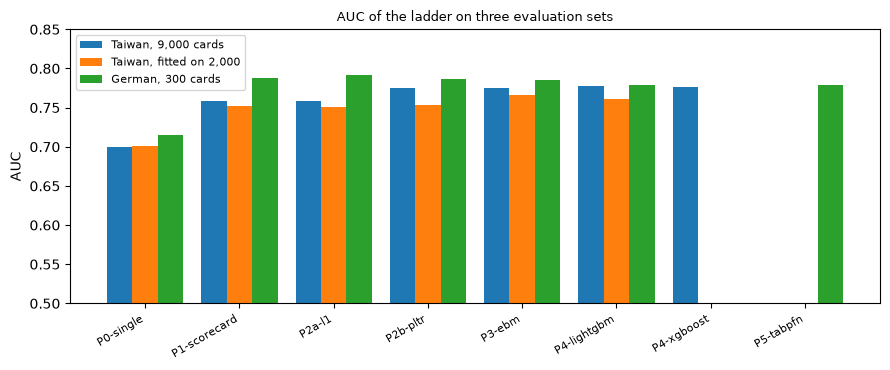

In [11]:
# The engine's AUC and Hosmer-Lemeshow on the two small-data cases, rebuilt from their CAP steps and reliability bins
sets = (("small", small), ("twin", twin))
auc_small = {}
for name, doc in sets:
    n_all, d_all = doc["outputs"]["n"], doc["outputs"]["defaults"]
    for rung in [m["id"] for m in doc["model"]]:
        out = doc["outputs"]["rungs"][rung]
        per_slice = np.rint(np.diff(np.array(out["cap"]["defaults"])) * d_all).astype(int)
        size = n_all // len(per_slice)
        risk = np.repeat(np.arange(len(per_slice), 0, -1), size)
        flags = np.concatenate([np.r_[np.ones(d), np.zeros(max(size - d, 0))] for d in per_slice])
        auc_small[(name, rung)] = disc_auc(risk, flags, policy=policy, model_id=rung).metric
p5 = next(m for m in models_german["model"] if m["id"] == "P5-tabpfn")
print("P5 engine and version:", p5["engine"], p5["engine_version"])
twin_auc = {r: round(a, 3) for (n, r), a in auc_small.items() if n == "twin"}
small_auc = {r: round(a, 3) for (n, r), a in auc_small.items() if n == "small"}
print("engine AUC on the German twin:", twin_auc)
print("engine AUC, Taiwan models fitted on 2000 rows:", small_auc)
fig, ax = plt.subplots(figsize=(9, 3.8))
names_sets = ["Taiwan, 9,000 cards", "Taiwan, fitted on 2,000", "German, 300 cards"]
shown = ladder[1:] + ["P5-tabpfn"]
for k, (label, name) in enumerate(zip(names_sets, ("big", "small", "twin"))):
    values = [engine[r][0] if name == "big" and r in engine else auc_small.get((name, r), np.nan) for r in shown]
    ax.bar(np.arange(len(shown)) + (k - 1) * 0.27, values, width=0.27, label=label)
ax.set_xticks(range(len(shown)), shown, rotation=30, ha="right", fontsize=8)
ax.set_ylim(0.5, 0.85)
ax.set_ylabel("AUC")
ax.set_title("AUC of the ladder on three evaluation sets", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

**Answer:** On 9,000 held-out Taiwan cards the richer challengers rank better by a few AUC points, and none of them wins once calibration is weighed. The engine, run on the cards rebuilt from the committed curves, gives AUC 0.7586 for the scorecard, 0.775 for the penalised trees, 0.7753 for the boosting machine, 0.7778 for LightGBM and 0.7765 for XGBoost, against 0.6994 for one variable: a gain of 0.016 to 0.019 points, with a 95% half-width of about 0.012 on each estimate. The scorecard ties the penalised logistic regression (0.7586). By grade, the chi-square p-value is 0.0264 (amber) for the scorecard, 0.4641 (green) for the penalised trees, and 0.0007 or 0.0 (red) for the boosting machine, LightGBM and XGBoost, while the level test is green for all eight (0.31 to 0.836). The one challenger that keeps the ranking gain and the fit is the penalised trees, whose 101 rules are unstable across resamples (mean Jaccard 0.411). The monotone boosted trees keep the scorecard's direction (largest violation 0.0), and the isotonic map brings the ECE of the boosting machine from 0.0218 to 0.0118 but worsens that of LightGBM from 0.0121 to 0.0134.

On small data the ranking advantage disappears: on the 300 German records the engine gives 0.788 for the scorecard, 0.791 for the penalised logistic regression, 0.785 for the boosting machine, 0.778 for LightGBM and 0.779 for TabPFN, and the Taiwan models fitted on 2,000 rows are at 0.752 for the scorecard and 0.766 for the boosting machine. The foundation model, with licence conditions on its weights, does not beat the scorecard here. The scikit-learn reference agrees with the engine on the AUC and the Brier score to better than one millionth (largest gaps 0.0 and 0.0).

What this notebook does not show: a refit of any challenger (the models were fitted by the pipeline on raw data, and the packages that fit them are not in the notebook environment), a paired DeLong test between the challengers on all 9,000 cards (the paired scores are not committed, only the rows of the battery), and the isotonic map fitted again on a calibration slice.

## Summary

- The research of this product found that tree ensembles beat a plain logistic regression by a few AUC points on retail credit, that glass-box variants recover interpretability, that calibration is separate from ranking, and that tabular foundation models are strongest on small data under licence restrictions; the committed ladder reproduces each statement on its own data.
- The engine's AUC, chi-square over grades, level test and paired challenger protocol put every model on the same footing, and `scikit-learn` agrees with it on the AUC and the Brier score.
- The glass boxes can be read: rules and their instability, shape functions beside the scorecard's contributions, constraints with a stored check.
- An isotonic map repairs the miscalibration of the boosting machine and adds noise to LightGBM; on 300 records the ranking advantage of the richer models disappears.

**What to try next.** Print the committed `reliability_raw` and `reliability` of XGBoost next to those of the boosting machine and see which bins move; then continue with notebook 07, which measures what the leakage-safe protocol of the whole topic enforces.

## References

- Baesens, B., Van Gestel, T., Viaene, S., Stepanova, M., Suykens, J. and Vanthienen, J. (2003), Journal of the Operational Research Society 54(6). https://doi.org/10.1057/palgrave.jors.2601545
- Lessmann, S., Baesens, B., Seow, H.-V. and Thomas, L. C. (2015), European Journal of Operational Research 247(1). https://doi.org/10.1016/j.ejor.2015.05.030
- Gunnarsson, B. R., vanden Broucke, S., Baesens, B., Oskarsdottir, M. and Lemahieu, W. (2021), Deep learning for credit scoring: do or don't?, European Journal of Operational Research 295(1). https://doi.org/10.1016/j.ejor.2021.03.006
- Grinsztajn, L., Oyallon, E. and Varoquaux, G. (2022), Why do tree-based models still outperform deep learning on typical tabular data?, NeurIPS 2022 Datasets and Benchmarks. https://arxiv.org/abs/2207.08815
- Dumitrescu, E., Hue, S., Hurlin, C. and Tokpavi, S. (2022), penalised logistic tree regression, European Journal of Operational Research 297(3). https://doi.org/10.1016/j.ejor.2021.06.053
- Lou, Y., Caruana, R., Gehrke, J. and Hooker, G. (2013), Accurate intelligible models with pairwise interactions, KDD 2013. https://doi.org/10.1145/2487575.2487579
- Nori, H., Jenkins, S., Koch, P. and Caruana, R. (2019), InterpretML: a unified framework for machine learning interpretability. https://arxiv.org/abs/1909.09223
- van den Goorbergh, R., van Smeden, M., Timmerman, D. and Van Calster, B. (2022), The harm of class imbalance corrections for risk prediction models, JAMIA 29(9). https://doi.org/10.1093/jamia/ocac093
- King, G. and Zeng, L. (2001), Logistic regression in rare events data, Political Analysis 9(2). https://doi.org/10.1093/oxfordjournals.pan.a004868
- Zadrozny, B. and Elkan, C. (2002), Transforming classifier scores into accurate multiclass probability estimates, KDD 2002. https://doi.org/10.1145/775047.775151
- Hollmann, N. et al. (2025), Accurate predictions on small data with a tabular foundation model, Nature 637. https://doi.org/10.1038/s41586-024-08328-6 ; the weights licences are those of the project README, https://github.com/PriorLabs/TabPFN
- XGBoost documentation, monotonic constraints. https://xgboost.readthedocs.io/en/stable/tutorials/monotonic.html ; LightGBM documentation, parameters. https://lightgbm.readthedocs.io/en/latest/Parameters.html
- DeLong, E. R., DeLong, D. M. and Clarke-Pearson, D. L. (1988), Comparing the areas under two or more correlated receiver operating characteristic curves, Biometrics 44(3). https://doi.org/10.2307/2531595
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients ; Statlog German Credit Data, UCI (CC BY 4.0). https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data